In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/merged.csv")
df["HourDK"] = pd.to_datetime(df["HourDK"], utc=True).dt.tz_convert("Europe/Copenhagen")
df = df.sort_values(["area", "HourDK"]).reset_index(drop=True)

df["date"] = df["HourDK"].dt.date
df["hour"] = df["HourDK"].dt.hour
df["month"] = df["HourDK"].dt.month

# The data is a UTC year, so in Danish time the last row (00:00 on 1 Jan 2025) belongs to 2025. Drop it.
df = df[df["HourDK"].dt.year == 2024]

# Check: how many hours does each day have?
hours_per_day = df.groupby(["area", "date"]).size()
print(hours_per_day.value_counts())
print(hours_per_day[hours_per_day != 24])

24    728
23      4
Name: count, dtype: int64
area  date      
DK1   2024-01-01    23
      2024-03-31    23
DK2   2024-01-01    23
      2024-03-31    23
dtype: int64


In [6]:
WINDOW = 4  # hours

# Average price and CO2 over each block of 4 consecutive hours, done per area over the whole year,
# so a window starting at 22:00 can run into the next day.
# rolling(4) puts the average on the LAST hour of the block; shift(-3) moves it to the FIRST hour.
for area in ["DK1", "DK2"]:
    mask = df["area"] == area
    df.loc[mask, "price_4h"] = df.loc[mask, "price_eur_mwh"].rolling(WINDOW).mean().shift(-(WINDOW - 1))
    df.loc[mask, "co2_4h"] = df.loc[mask, "carbon_g_kwh"].rolling(WINDOW).mean().shift(-(WINDOW - 1))

# For each day, pick the window START hour (00:00 to 23:00) with the lowest price and the lowest CO2
rows = []
for (area, date), day in df.groupby(["area", "date"]):
    cheap_idx = day["price_4h"].idxmin()
    clean_idx = day["co2_4h"].idxmin()
    rows.append({
        "area": area,
        "date": date,
        "month": day["month"].iloc[0],
        "cheap_start": day.loc[cheap_idx, "hour"],
        "clean_start": day.loc[clean_idx, "hour"],
        "cheap_price": day.loc[cheap_idx, "price_4h"],
        "cheap_co2": day.loc[cheap_idx, "co2_4h"],
        "clean_price": day.loc[clean_idx, "price_4h"],
        "clean_co2": day.loc[clean_idx, "co2_4h"],
    })

windows = pd.DataFrame(rows)
windows["same"] = windows["cheap_start"] == windows["clean_start"]
windows["overlap"] = (windows["cheap_start"] - windows["clean_start"]).abs() < WINDOW

# How far apart are the two windows?
windows["extra_co2"] = windows["cheap_co2"] - windows["clean_co2"]               # g/kWh you accept by choosing cheap
windows["extra_co2_pct"] = 100 * windows["extra_co2"] / windows["clean_co2"]     # same, in %
windows["extra_price"] = windows["clean_price"] - windows["cheap_price"]          # EUR/MWh you pay by choosing clean
windows["near_clean"] = windows["extra_co2_pct"] <= 5                             # cheap window is within 5% of the cleanest

print(len(windows), "area-days")
print(windows.groupby("area")[["same", "overlap", "near_clean"]].mean().round(2))
print(windows.groupby("area")[["extra_co2", "extra_co2_pct", "extra_price"]].median().round(1))
print(windows.groupby(["area", "cheap_start"]).size().unstack("area"))

732 area-days
      same  overlap  near_clean
area                           
DK1   0.11     0.30        0.17
DK2   0.11     0.34        0.31
      extra_co2  extra_co2_pct  extra_price
area                                       
DK1        30.3           50.5         17.9
DK2         7.8           15.5         17.2
area           DK1   DK2
cheap_start             
0             30.0  28.0
1             43.0  46.0
2             27.0  28.0
3             14.0  10.0
4              2.0   2.0
5              NaN   2.0
9              NaN   1.0
10             7.0   4.0
11            33.0  44.0
12           102.0  92.0
13            39.0  30.0
14             4.0   2.0
20             4.0   2.0
22             NaN   3.0
23            61.0  72.0


       same       near_clean       extra_co2        extra_price       
area    DK1   DK2        DK1   DK2       DK1    DK2         DK1    DK2
month                                                                 
1      0.13  0.19       0.23  0.35     27.27   3.96        4.86  16.23
2      0.03  0.07       0.03  0.31     35.25   6.92       11.15  11.24
3      0.03  0.13       0.10  0.26     33.96   6.31        9.79  12.27
4      0.07  0.10       0.10  0.20     55.00  18.90       29.71  20.34
5      0.06  0.06       0.13  0.23     50.77  33.79       27.78  18.36
6      0.03  0.10       0.03  0.23     59.19  17.94       45.30  28.68
7      0.10  0.03       0.13  0.35     59.40  37.98       35.76  26.65
8      0.10  0.10       0.19  0.32     25.06  20.90       33.19  24.80
9      0.20  0.13       0.30  0.33     48.49  23.56       39.68  26.69
10     0.16  0.06       0.19  0.29     24.46   9.00       18.56  23.54
11     0.27  0.20       0.43  0.43      4.48   2.77        3.30   7.38
12    

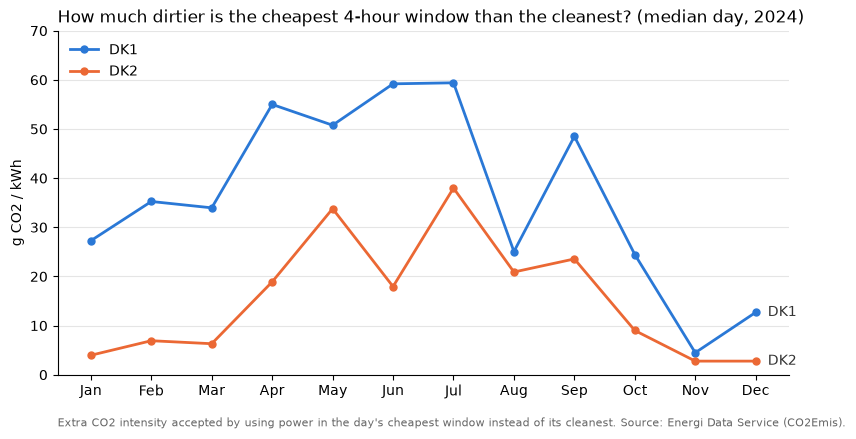

In [7]:
# Monthly summary: share of days that match, and the median size of the gap
monthly = windows.groupby(["month", "area"]).agg(
    same=("same", "mean"),
    near_clean=("near_clean", "mean"),
    extra_co2=("extra_co2", "median"),
    extra_price=("extra_price", "median"),
).unstack("area").round(2)
print(monthly)

# Same thing by season (meteorological seasons)
season_of_month = {12: "Winter", 1: "Winter", 2: "Winter",
                   3: "Spring", 4: "Spring", 5: "Spring",
                   6: "Summer", 7: "Summer", 8: "Summer",
                   9: "Autumn", 10: "Autumn", 11: "Autumn"}
windows["season"] = windows["month"].map(season_of_month)
seasonal = windows.groupby(["season", "area"]).agg(
    same=("same", "mean"),
    near_clean=("near_clean", "mean"),
    extra_co2=("extra_co2", "median"),
    extra_price=("extra_price", "median"),
).unstack("area").round(2)
seasonal = seasonal.loc[["Winter", "Spring", "Summer", "Autumn"]]  # put seasons in calendar order
print(seasonal)

# Chart: how much dirtier is the cheapest window than the cleanest, by month
colors = {"DK1": "#2a78d6", "DK2": "#eb6834"}
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for area in ["DK1", "DK2"]:
    values = monthly[("extra_co2", area)]
    ax.plot(range(1, 13), values, color=colors[area], linewidth=2, marker="o", markersize=5, label=area)
    ax.text(12.2, values.iloc[-1], area, color="#333333", va="center")  # label at the end of each line

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_ylim(0, 70)
ax.set_ylabel("g CO2 / kWh")
ax.set_title("How much dirtier is the cheapest 4-hour window than the cleanest? (median day, 2024)", loc="left")
ax.text(0, -0.15, "Extra CO2 intensity accepted by using power in the day's cheapest window instead of its cleanest. "
        "Source: Energi Data Service (CO2Emis).", transform=ax.transAxes, fontsize=8, color="#666666")
ax.grid(axis="y", color="#e5e5e5")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [8]:
ENERGY_KWH = 10   # needed per night; at 11 kW this takes ~55 min, so it fits in one hour
ETS_PRICE = 65    # EUR/t, 2024 average EU ETS allowance price (EEA)

# Keep only plug-in hours: 18:00-23:00 and 00:00-06:00 (unplug at 07:00)
ev = df[(df["hour"] >= 18) | (df["hour"] <= 6)].copy()

# Give every hour a "night" label = the date the car was plugged in.
# Hours after midnight belong to the previous evening's night.
ev["night"] = pd.to_datetime(ev["date"])
ev.loc[ev["hour"] <= 6, "night"] = ev["night"] - pd.Timedelta(days=1)

# Check: a normal night has 13 hours
hours_per_night = ev.groupby(["area", "night"]).size()
print(hours_per_night.value_counts())
print(hours_per_night[hours_per_night != 13])

# Drop the two incomplete nights at the edges of the year
ev = ev[ev["night"].between("2024-01-01", "2024-12-30")]

# For each night, pick the hour for each strategy
rows = []
for (area, night), n in ev.groupby(["area", "night"]):
    plugin_idx = n["HourDK"].idxmin()          # first hour = 18:00, charge immediately
    cheap_idx = n["price_eur_mwh"].idxmin()    # cheapest hour of the night
    clean_idx = n["carbon_g_kwh"].idxmin()     # cleanest hour of the night
    for strategy, idx in [("immediate", plugin_idx), ("cheapest", cheap_idx), ("cleanest", clean_idx)]:
        rows.append({
            "area": area,
            "night": night,
            "strategy": strategy,
            "hour": n.loc[idx, "hour"],
            "cost_eur": n.loc[idx, "price_eur_mwh"] * ENERGY_KWH / 1000,  # EUR/MWh x MWh
            "co2_kg": n.loc[idx, "carbon_g_kwh"] * ENERGY_KWH / 1000,     # g/kWh x kWh -> kg
        })
charging = pd.DataFrame(rows)

# Totals per year
yearly = charging.groupby(["area", "strategy"])[["cost_eur", "co2_kg"]].sum().round(1)
print(yearly)

# Cost of CO2 avoided: going from cheapest to cleanest
for area in ["DK1", "DK2"]:
    extra_eur = yearly.loc[(area, "cleanest"), "cost_eur"] - yearly.loc[(area, "cheapest"), "cost_eur"]
    saved_t = (yearly.loc[(area, "cheapest"), "co2_kg"] - yearly.loc[(area, "cleanest"), "co2_kg"]) / 1000
    print(f"{area}: pay {extra_eur:.0f} EUR/year more to save {saved_t * 1000:.0f} kg CO2 "
          f"-> {extra_eur / saved_t:.0f} EUR per tonne (ETS: {ETS_PRICE})")

# Which hours does each strategy pick?
pd.crosstab([charging["area"], charging["strategy"]], charging["hour"])

13    728
6       4
12      2
Name: count, dtype: int64
area  night     
DK1   2023-12-31     6
      2024-03-30    12
      2024-12-31     6
DK2   2023-12-31     6
      2024-03-30    12
      2024-12-31     6
dtype: int64
                cost_eur  co2_kg
area strategy                   
DK1  cheapest      192.4   352.3
     cleanest      255.1   235.8
     immediate     357.3   378.5
DK2  cheapest      184.2   259.3
     cleanest      269.9   207.1
     immediate     362.1   259.0
DK1: pay 63 EUR/year more to save 116 kg CO2 -> 538 EUR per tonne (ETS: 65)
DK2: pay 86 EUR/year more to save 52 kg CO2 -> 1642 EUR per tonne (ETS: 65)


hour            0   1   2   3   4   5   6    18  19  20  21  22  23
area strategy                                                      
DK1  cheapest   22  24  34  85  80  36  26   27   4   0   3   8  16
     cleanest   22  30  17  26  23  15  43   46  30  23  16  33  41
     immediate   0   0   0   0   0   0   0  365   0   0   0   0   0
DK2  cheapest   18  21  41  85  82  38  23   22   2   2   0   5  26
     cleanest   16  23  15  10   9  17  57  103  27  22  24  21  21
     immediate   0   0   0   0   0   0   0  365   0   0   0   0   0

In [9]:
results = []
for plugin_hour in [16, 17, 18, 19, 20, 21]:
    # Same steps as cell 4, but with a different plug-in hour
    ev = df[(df["hour"] >= plugin_hour) | (df["hour"] <= 6)].copy()
    ev["night"] = pd.to_datetime(ev["date"])
    ev.loc[ev["hour"] <= 6, "night"] = ev["night"] - pd.Timedelta(days=1)
    ev = ev[ev["night"].between("2024-01-01", "2024-12-30")]

    for (area, night), n in ev.groupby(["area", "night"]):
        plugin_idx = n["HourDK"].idxmin()
        cheap_idx = n["price_eur_mwh"].idxmin()
        clean_idx = n["carbon_g_kwh"].idxmin()
        for strategy, idx in [("immediate", plugin_idx), ("cheapest", cheap_idx), ("cleanest", clean_idx)]:
            results.append({
                "plugin_hour": plugin_hour,
                "area": area,
                "strategy": strategy,
                "cost_eur": n.loc[idx, "price_eur_mwh"] * ENERGY_KWH / 1000,
                "co2_kg": n.loc[idx, "carbon_g_kwh"] * ENERGY_KWH / 1000,
            })

results = pd.DataFrame(results)

# Yearly totals: one row per area and plug-in hour, one column per strategy
yearly_sens = results.groupby(["area", "plugin_hour", "strategy"])[["cost_eur", "co2_kg"]].sum().unstack("strategy")
print(yearly_sens.round(0))

# EUR per tonne avoided, cheapest -> cleanest
extra_eur = yearly_sens[("cost_eur", "cleanest")] - yearly_sens[("cost_eur", "cheapest")]
saved_t = (yearly_sens[("co2_kg", "cheapest")] - yearly_sens[("co2_kg", "cleanest")]) / 1000
print((extra_eur / saved_t).round(0).unstack("area"))

                 cost_eur                      co2_kg                   
strategy         cheapest cleanest immediate cheapest cleanest immediate
area plugin_hour                                                        
DK1  16             150.0    230.0     237.0    362.0    219.0     392.0
     17             180.0    244.0     312.0    353.0    230.0     383.0
     18             192.0    255.0     357.0    352.0    236.0     378.0
     19             195.0    259.0     389.0    352.0    239.0     381.0
     20             195.0    254.0     377.0    353.0    242.0     372.0
     21             196.0    248.0     327.0    354.0    246.0     362.0
DK2  16             148.0    237.0     244.0    284.0    199.0     288.0
     17             173.0    252.0     317.0    263.0    203.0     267.0
     18             184.0    270.0     362.0    259.0    207.0     259.0
     19             187.0    276.0     393.0    260.0    211.0     261.0
     20             188.0    266.0     379.0    260

# Flexibility: does chasing cheap hours also mean clean hours?

## 1. Daily window metric

**Method**
- For each day and area: the cheapest and the cleanest contiguous 4-hour window (average day-ahead price and average CO2 intensity over 4 consecutive hours).
- A day = window *start* hours 00:00 to 23:00 in Danish time. Windows may run past midnight (computed on the full hourly series, not per calendar day). An earlier per-day version piled up artificial windows at 20:00, the last start the day allowed; headline numbers barely changed after the fix.
- 366 days x 2 areas = 732 area-days. 1 Jan has 23 hours (UTC download), 31 Mar has 23 (clocks forward); one window on 27 Oct spans the missing hour.
- Measures:
  - `same`: identical start hour
  - `overlap`: windows share at least one hour
  - `near_clean`: cheapest window's CO2 within 5% of the cleanest (threshold is my choice)
  - `extra_co2`: g/kWh accepted by choosing the cheapest window instead of the cleanest
  - `extra_price`: EUR/MWh paid by choosing the cleanest window instead of the cheapest

**Results (full year)**

| | Same | Overlap | Near-clean | Extra CO2 (median) | Extra price (median) |
|---|---|---|---|---|---|
| DK1 | 11% | 30% | 17% | 30 g/kWh (+51%) | 18 EUR/MWh |
| DK2 | 11% | 34% | 31% | 8 g/kWh (+16%) | 17 EUR/MWh |

- On about 9 days in 10, the cheapest 4-hour window is not the cleanest, in both areas.

**By season (median day)**

| | DK1 extra CO2 | DK2 extra CO2 | DK1 extra price | DK2 extra price |
|---|---|---|---|---|
| Winter (Dec-Feb) | 24 g/kWh | 4 g/kWh | 10 EUR/MWh | 15 EUR/MWh |
| Spring (Mar-May) | 45 | 11 | 22 | 16 |
| Summer (Jun-Aug) | 49 | 23 | 36 | 26 |
| Autumn (Sep-Nov) | 15 | 7 | 14 | 16 |

- The *share* of matching days shows no clear seasonal pattern (Nov is the best month: 27% DK1, 20% DK2 same window).
- The *size* of the miss is seasonal: small in winter, large in spring and summer. This matches finding 3.5/3.6 in 02_exploration (summer midday imports from Germany/Netherlands make the cheap hours dirtier).
- DK1's gap is larger every month: DK2's CO2 barely varies, so there is less to gain by shifting.
- On a given day cheap and clean can be far apart even in winter (e.g. DK1 2 Jan: cheapest window 202 g/kWh, cleanest 70 g/kWh). Hour-of-day averages hide this day-to-day variation, which depends on when the wind blows.

## 2. EV charging simulation

**Method**
- EV needs 10 kWh per night, 11 kW charger, plugged in 18:00 to 07:00 Danish time. 10 kWh at 11 kW takes ~55 min, so each strategy picks one hour (last possible start 06:00).
- Each hour gets a `night` label = plug-in date (hours 00:00-06:00 belong to the previous evening). 365 full nights per area (1 Jan to 30 Dec); the partial nights at the edges of the year are dropped. Night of 30 Mar has 12 hours (DST).
- Strategies: **immediate** (18:00), **cheapest** (lowest price hour), **cleanest** (lowest CO2 hour).
- Cost = day-ahead price x 10 kWh. CO2 = intensity x 10 kWh.

**Results (per year, plug-in 18:00)**

| | Immediate | Cheapest | Cleanest |
|---|---|---|---|
| DK1 | 357 EUR, 379 kg | 192 EUR, 352 kg | 255 EUR, 236 kg |
| DK2 | 362 EUR, 259 kg | 184 EUR, 259 kg | 270 EUR, 207 kg |

- Immediate -> cheapest saves ~165-180 EUR/year in both areas. It cuts CO2 by ~7% in DK1 and not at all in DK2.
- Cheapest -> cleanest:
  - DK1: +63 EUR/year to save 116 kg -> **538 EUR/t CO2**
  - DK2: +86 EUR/year to save 52 kg -> **1,642 EUR/t CO2**
- 2024 EU ETS average price: ~65 EUR/t (EEA: 64.8 EUR/t; other series give 66.5-67). Going green through EV timing costs 8x (DK1) to 25x (DK2) the carbon price.

**Check: why is the cleanest hour often 18:00 (DK2: 103 of 365 nights)?**
- In DK2 CO2 falls through the afternoon (summer: 109 g/kWh at 14:00 -> 78 at 17-18:00), then rises again to ~86 at 20:00. So early evening is often a genuine low point, after the solar-hour imports and while the evening price peak pulls in Nordic hydro.
- Opening the window at 17:00 moves the pile-up to 17:00 (100 nights). The cleanest hour is often at or before plug-in. This is a real constraint (the car isn't there earlier), not a calendar artifact, but it makes results depend on plug-in time, so I tested that.

**Sensitivity: plug-in time 16:00 to 21:00 (EUR per tonne avoided, cheapest -> cleanest)**

| Plug-in | 16:00 | 17:00 | 18:00 | 19:00 | 20:00 | 21:00 |
|---|---|---|---|---|---|---|
| DK1 | 562 | 521 | 538 | 566 | 528 | 486 |
| DK2 | 1,046 | 1,307 | 1,642 | 1,818 | 1,706 | 1,416 |

- Always at least 7x the ETS price. The headline does not depend on the 18:00 assumption.
- The savings from smart charging do depend on it: immediate charging costs 237-393 EUR/year depending on whether you hit the evening price peak.
- In DK2, cheapest and immediate have about the same CO2 at every plug-in time: chasing price there saves money but not CO2.

## 3. Caveats
- **Spot price only.** Household bills add grid tariffs (time-of-use, with an evening peak), electricity tax and VAT. Immediate charging would cost more in reality, so the EUR savings from smart charging are understated. EUR per tonne avoided would also change.
- **Average, not marginal, CO2.** "Avoided" CO2 is the average mix of the hour you charge in, not the emissions change caused by shifting load. This matters most for the comparison with the ETS price.
- **One EV, 10 kWh/night, one-hour charge.** Picking the single best hour is the best case for flexibility. Larger energy needs spread over more hours would narrow the gaps.
- **CO2Emis caveats from 02_exploration still apply:** real-time estimate, 125% CHP method, treatment of imports to be confirmed.
- **"Winter" combines Jan-Feb 2024 and Dec 2024**, not one continuous winter. Single months (~30 days) are noisy; use seasons for claims.
- **The 5% `near_clean` threshold is a choice.** The g/kWh gap is the main measure.

## 4. Sources
- Energi Data Service (Energinet): Elspotprices, ProductionConsumptionSettlement, CO2Emis, 2024.
- EU ETS 2024 average price: [EEA, use of auctioning revenues](https://www.eea.europa.eu/en/analysis/indicators/use-of-auctioning-revenues-generated); [ETC CM Report 2025/06](https://www.eionet.europa.eu/etcs/etc-cm/products/etc-cm-report-2025-06/@@download/file/ETS-Report_2025_final.pdf) (64.76 EUR/t).

## 5. Next steps
- [ ] Chart 1: hour-of-day profiles, price (top) and CO2 (bottom) panels, winter vs summer, DK1 and DK2
- [ ] Chart 2: monthly extra CO2 of the cheapest window
- [ ] Chart 3: EV strategies, EUR/year vs kg CO2/year
- [ ] Chart 4: EUR per tonne avoided with the 16:00-21:00 range, vs the ETS price